# CSC2042S
## Assignment 3: Neural Networks
### Total marks: 30


#### Assignment goal: Optimisation of a Neural Network for Image Classification

This Jupyter Notebook will guide you through building a neural network, understanding the training process including backpropagation), and experimentally discovering how hyperparameters impact performance.

**Dataset: Fashion-MNIST** - A collection of 70,000 grayscale images of clothing items, perfect for testing your models.
https://www.kaggle.com/datasets/zalando-research/fashionmnist

## Part 1: Setup and Data Loading

* Import necessary libraries, such as ``torch``, ``torch.nn``, ``torchvision.transforms``, ``matplotlib.pyplot``, etc.

* Load the dataset and transform the dataset (convert to tensors, normalise). Load the Fashion_mNIST dataset into ``DataLoader`` objects for training and validation.

Data partitioning: Download the 60,000-image training dataset and split it into:
50,000 samples for training.
10,000 samples for validation.
Take into account Normalisation.


In [1]:
# Import libraries
from pathlib import Path
import numpy as np
import struct
import torch
from torch.utils.data import TensorDataset, DataLoader



data_dir = Path("data")
train_images_path = data_dir / "train-images-idx3-ubyte"
train_labels_path = data_dir / "train-labels-idx1-ubyte"
test_images_path = data_dir / "t10k-images-idx3-ubyte"
test_labels_path = data_dir / "t10k-labels-idx1-ubyte"

# Read data from the MNIST files
with open(train_images_path, 'rb') as f:
    magic_number, num_images, rows, cols = struct.unpack('>IIII', f.read(16))
    train_images = np.frombuffer(f.read(), dtype=np.uint8).reshape(num_images, rows, cols)

with open(train_labels_path, 'rb') as f:
    magic_number, num_labels = struct.unpack('>II', f.read(8))
    train_labels = np.frombuffer(f.read(), dtype=np.uint8)

with open(test_images_path, 'rb') as f:
    magic_number, num_images, rows, cols = struct.unpack('>IIII', f.read(16))
    test_images = np.frombuffer(f.read(), dtype=np.uint8).reshape(num_images, rows, cols)

with open(test_labels_path, 'rb') as f:
    magic_number, num_labels = struct.unpack('>II', f.read(8))
    test_labels = np.frombuffer(f.read(), dtype=np.uint8)

# Convert to tensors & scale to [0, 1] 
train_images = torch.tensor(train_images, dtype=torch.float32) / 255.0
train_images = train_images.unsqueeze(1)  
train_labels = torch.tensor(train_labels, dtype=torch.long)

test_images = torch.tensor(test_images, dtype=torch.float32) / 255.0
test_images = test_images.unsqueeze(1)   
test_labels = torch.tensor(test_labels, dtype=torch.long)

# Split indices 50,000 train / 10,000 validation
generator = torch.Generator().manual_seed(42)
perm = torch.randperm(len(train_images), generator=generator)
train_indices = perm[:50000]
val_indices   = perm[50000:]

# Compute mean and std using ONLY the 50,000 training images
train_mean = train_images[train_indices].mean()
train_std  = train_images[train_indices].std()

print("Training set normalisation statistics (from 50,000 training images):")
print(f"  Mean: {train_mean:.4f}")
print(f"  Std:  {train_std:.4f}")

# Normalize the training and test images
train_images = (train_images - train_mean) / train_std
test_images  = (test_images  - train_mean) / train_std

# Load data
train_dataset = TensorDataset(train_images[train_indices], train_labels[train_indices])
val_dataset   = TensorDataset(train_images[val_indices],   train_labels[val_indices])
test_dataset  = TensorDataset(test_images, test_labels)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

# Runtime check
print(f"\nTraining set size:   {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size:       {len(test_dataset)}")

train_batch_imgs, train_batch_lbls = next(iter(train_loader))
val_batch_imgs, val_batch_lbls = next(iter(val_loader))

print(f"\nTrain batch images shape: {train_batch_imgs.shape}, labels shape: {train_batch_lbls.shape}")
print(f"Train batch pixel range:  [{train_batch_imgs.min():.2f}, {train_batch_imgs.max():.2f}]")
print(f"Train batch label range:  [{train_batch_lbls.min()}, {train_batch_lbls.max()}]")

print(f"\nVal batch images shape:   {val_batch_imgs.shape}, labels shape: {val_batch_lbls.shape}")
print(f"Val batch pixel range:    [{val_batch_imgs.min():.2f}, {val_batch_imgs.max():.2f}]")
print(f"Val batch label range:    [{val_batch_lbls.min()}, {val_batch_lbls.max()}]")



Training set normalisation statistics (from 50,000 training images):
  Mean: 0.2857
  Std:  0.3529

Training set size:   50000
Validation set size: 10000
Test set size:       10000



Train batch images shape: torch.Size([64, 1, 28, 28]), labels shape: torch.Size([64])
Train batch pixel range:  [-0.81, 2.02]
Train batch label range:  [0, 9]

Val batch images shape:   torch.Size([64, 1, 28, 28]), labels shape: torch.Size([64])
Val batch pixel range:    [-0.81, 2.02]
Val batch label range:    [0, 9]


## Part 2: Building and Training a Baseline Model [5 Marks]

Before we can optimise a model, we need a baseline to compare against. We will build a simple, standard neural network and train it with default settings.

**Define the Network Architecture**
Define a PyTorch class for your neural network that inherits from ``nn.Module``. Your model should be a simple Multi-Layer Perceptron (MLP) with the following architecture:

* Input Layer (a flattening layer).

* Hidden Layer 1: 128 neurons, ReLU activation.

* Hidden Layer 2: 64 neurons, ReLU activation.

* Output Layer: 10 neurons (one for each class).

**Training Loop**
Complete the provided ``train_model`` function. You will need to fill in the essential steps of the training process within the loop. This is where you will implement the logic for the forward pass, loss calculation, backpropagation, and weight updates.

**Train the Baseline Model**
Create an instance of your model, define a loss function, and an optimiser. Train your model for 10 epochs and record its final accuracy on the validation set. This is your baseline accuracy.

In [2]:
# Define Network Architecture [2 Marks]
import torch 
import torch.nn as nn
import torch.optim as optim

class BaselineMLP(nn.Module):
    def __init__(self):
        super(BaselineMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
      x = self.flatten(x)
      x = self.relu(self.fc1(x))
      x = self.relu(self.fc2(x))
      x = self.fc3(x)
      return x

In [3]:
# Updated Training and Evaluation skeleton [3 Marks]
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    """
    Trains a model and validates it each epoch.
    Returns: A dictionary containing lists of training loss, validation loss,
             and validation accuracy for each epoch.
    """
    # Data structure to store metrics
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    print("Starting Training...")
    for epoch in range(epochs):
        model.train() # Set model to training mode
        running_train_loss = 0.0
        for images, labels in train_loader:
            optimizer.zero_grad() # Zero the gradients
            outputs = model(images) # Forward pass
            loss = criterion(outputs, labels) # Compute loss
            loss.backward() # Backward pass
            optimizer.step() # Update weights
            running_train_loss += loss.item() * images.size(0)
            

        # Calculate and store average training loss for the epoch
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        history['train_loss'].append(epoch_train_loss)

        # 2. Validation Phase
        model.eval() # Set model to evaluation mode
        running_val_loss = 0.0
        correct_predictions = 0
        total_predictions = 0

        with torch.no_grad(): # Disable gradient calculations
            for images, labels in val_loader:
                outputs = model(images) # Forward pass
                loss = criterion(outputs, labels) # Compute loss
                running_val_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                correct_predictions += (predicted == labels).sum().item()
                total_predictions += labels.size(0)
   

        # Calculate and store average validation loss and accuracy
        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct_predictions / total_predictions
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

    print("Finished Training")
    return history

In [4]:
# Train the Baseline Model [3 Marks]
torch.manual_seed(42)
model = BaselineMLP()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

baseline_history = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10)
baseline_model = model

# Measure training accuracy on the trained baseline (not the separate Run 5 repeat).
baseline_model.eval()
correct_train = 0
with torch.no_grad():
    for images, labels in train_loader:
        predictions = baseline_model(images).argmax(dim=1)
        correct_train += (predictions == labels).sum().item()
baseline_train_acc = correct_train / len(train_loader.dataset)

print(f"\nBaseline training accuracy:   {baseline_train_acc * 100:.2f}%")
print(f"Baseline validation accuracy: {baseline_history['val_acc'][-1] * 100:.2f}%")

Starting Training...


Epoch 1/10 - Train Loss: 0.4958, Val Loss: 0.4180, Val Acc: 0.8453


Epoch 2/10 - Train Loss: 0.3618, Val Loss: 0.3883, Val Acc: 0.8601


Epoch 3/10 - Train Loss: 0.3239, Val Loss: 0.3379, Val Acc: 0.8776


Epoch 4/10 - Train Loss: 0.2976, Val Loss: 0.3285, Val Acc: 0.8797


...

Epoch 7/10 - Train Loss: 0.2489, Val Loss: 0.3091, Val Acc: 0.8903


Epoch 8/10 - Train Loss: 0.2343, Val Loss: 0.3214, Val Acc: 0.8882


Epoch 9/10 - Train Loss: 0.2242, Val Loss: 0.3105, Val Acc: 0.8890


Epoch 10/10 - Train Loss: 0.2142, Val Loss: 0.3281, Val Acc: 0.8852
Finished Training



Baseline training accuracy:   92.20%
Baseline validation accuracy: 88.52%


## Part 3: Hyperparameter Optimisation Experiment [10 Marks]

Remember the definition of hyperparameters - they are external configuration variables set before training begins, controlling the model's structure and the learning process itself.
The goal is to find the set of the values that beats the baseline accuracy.

**Design and run your experiment**
Choose **three** from the following categories of hyperparameters to investigate:
* Learning Processes
* Regularisation/Architecture
  

Write a script (e.g., using nested loops) that systematically trains and evaluates a new model for each combination of the hyperparameters you have chosen. Store the final validation accuracy for each run in a data structure.

In [5]:
# Hyperparameter Optimisation Experiment [15 Marks]
import time

# Definition of hyperparameters config
experiments = [
    # SGD runs
    {'optimizer_name': 'SGD',  'lr': 0.01,  'batch_size': 64},
    {'optimizer_name': 'SGD',  'lr': 0.01,  'batch_size': 128},
    {'optimizer_name': 'SGD',  'lr': 0.10,  'batch_size': 64},
    {'optimizer_name': 'SGD',  'lr': 0.10,  'batch_size': 128},
    # Adam runs
    {'optimizer_name': 'Adam', 'lr': 0.001, 'batch_size': 64},
    {'optimizer_name': 'Adam', 'lr': 0.001, 'batch_size': 128},
    {'optimizer_name': 'Adam', 'lr': 0.003, 'batch_size': 64},
    {'optimizer_name': 'Adam', 'lr': 0.003, 'batch_size': 128},
]

results = []
all_histories = []

best_val_acc = -1.0
best_model = None
best_history = None
best_config = None

criterion = nn.CrossEntropyLoss()
epochs = 10

print(f"Starting Hyperparameter Search: {len(experiments)} configurations, {epochs} epochs each...\n")
start_total_time = time.time()

for i, config in enumerate(experiments, 1):
    opt_name = config['optimizer_name']
    lr = config['lr']
    bs = config['batch_size']
    run_name = f"Run_{i}_{opt_name}_lr{lr}_bs{bs}"
    print(f"[{i}/{len(experiments)}] Running: {opt_name} | lr: {lr} | batch_size: {bs}")

    torch.manual_seed(42)
    model = BaselineMLP()

    # creating dataloaders for specific batch size
    exp_train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True)
    exp_val_loader   = DataLoader(val_dataset,   batch_size=bs, shuffle=False)

    if opt_name == 'SGD':
        optimizer = optim.SGD(model.parameters(), lr=lr)
    elif opt_name == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
        
    history = train_model(
        model = model,
        train_loader = exp_train_loader,
        val_loader = exp_val_loader,
        criterion = criterion,
        optimizer = optimizer,
        epochs = epochs
    )
    
    # Evaluate final training accuracy
    model.eval()
    correct_train = 0
    with torch.no_grad():
        for images, labels in exp_train_loader:
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            correct_train += (preds == labels).sum().item()
    final_train_acc = correct_train / len(exp_train_loader.dataset)

    final_train_loss = history['train_loss'][-1]
    final_val_loss = history['val_loss'][-1]
    final_val_acc = history['val_acc'][-1]
    
    record = {
        'Run': i,
        'Optimizer': opt_name,
        'Learning Rate': lr,
        'Batch Size': bs,
        'Final Train Loss': final_train_loss,
        'Final Train Acc (%)': round(final_train_acc * 100, 2),
        'Final Val Loss': final_val_loss,
        'Final Val Acc (%)': round(final_val_acc * 100, 2)
    }
    results.append(record)
    all_histories.append(history)
    
    if final_val_acc > best_val_acc:
        best_val_acc = final_val_acc
        best_model = model
        best_history = history
        best_config = config
    
    print(f"--> Result: Train Acc = {final_train_acc * 100:.2f}%, Val Acc = {final_val_acc * 100:.2f}%, Val Loss = {final_val_loss:.4f}\n")

total_duration = time.time() - start_total_time
print(f"Hyperparameter experiment completed in {total_duration / 60:.1f} minutes.")
print(f"Single Best Configuration: {best_config} with Validation Accuracy: {best_val_acc * 100:.2f}%")


Starting Hyperparameter Search: 8 configurations, 10 epochs each...

[1/8] Running: SGD | lr: 0.01 | batch_size: 64
Starting Training...


Epoch 1/10 - Train Loss: 0.9518, Val Loss: 0.6780, Val Acc: 0.7549


Epoch 2/10 - Train Loss: 0.5299, Val Loss: 0.5122, Val Acc: 0.8231


Epoch 3/10 - Train Loss: 0.4686, Val Loss: 0.4832, Val Acc: 0.8245


Epoch 4/10 - Train Loss: 0.4370, Val Loss: 0.4456, Val Acc: 0.8384


...

Epoch 7/10 - Train Loss: 0.2629, Val Loss: 0.3358, Val Acc: 0.8821


Epoch 8/10 - Train Loss: 0.2501, Val Loss: 0.3696, Val Acc: 0.8710


Epoch 9/10 - Train Loss: 0.2420, Val Loss: 0.3554, Val Acc: 0.8804


Epoch 10/10 - Train Loss: 0.2364, Val Loss: 0.3506, Val Acc: 0.8816
Finished Training


--> Result: Train Acc = 91.61%, Val Acc = 88.16%, Val Loss = 0.3506

Hyperparameter experiment completed in 0.7 minutes.
Single Best Configuration: {'optimizer_name': 'Adam', 'lr': 0.001, 'batch_size': 128} with Validation Accuracy: 89.04%


## Part 4: Analysis and Report  [10 Marks]
In this final section, you will analyse the results of your experiment and report your findings.

* Present your experimental results in a well-formatted table (e.g., a Pandas DataFrame) showing the combination of hyperparameters and the final validation accuracy for each run. [2 Marks]
* Create at least two visualisations to help interpret your results: [4 Marks]
    * Hyperparameter Impact: Create a bar chart or heatmap that clearly compares the performance of your different hyperparameter combinations.
    * Loss Curves. Plot the training and validation loss curves (loss vs. epochs) for your baseline model and your single best-performing model on the same graph. This is crucial for comparing model convergence and overfitting.
    * Confusion Matrix. Generate and display a confusion matrix for your best model's predictions on the validation set. This will help you see which specific clothing items are being confused.
* Interpret your results. [4 Marks]
  * Answer the following questions concisely, using evidence from your table and plots to support your claims:
    * Best vs. Baseline: Which combination of hyperparameters produced the best model? How much did it improve upon the baseline accuracy?
    * Hyperparameter Influence: Which hyperparameter had the most significant impact on performance? Explain why you think certain values worked better than others.
    * Overfitting Analysis: By comparing the loss curves of your baseline and best models, analyze the degree of overfitting. Did your hyperparameter tuning help mitigate overfitting? How can you tell from the plot?
    * Error Analysis: Look at your confusion matrix. Identify two classes that the model frequently confuses. Propose a reason for this confusion by considering the visual characteristics of the items in those classes.

**Table 1 — Training accuracy** (original baseline and eight runs)

,Model / Configuration,Optimizer,Learning Rate,Batch Size,Final Train Loss,Final Train Acc (%)
0,Original Baseline,Adam,0.001,64,0.2142,92.20
1,Run 1,SGD,0.010,64,0.3520,86.94
2,Run 2,SGD,0.010,128,0.4029,85.97
3,Run 3,SGD,0.100,64,0.2267,88.47
4,Run 4,SGD,0.100,128,0.2550,91.05
5,Run 5 (Baseline Repeat),Adam,0.001,64,0.2142,92.20
6,Run 6,Adam,0.001,128,0.2232,92.42
7,Run 7,Adam,0.003,64,0.2489,90.47
8,Run 8,Adam,0.003,128,0.2364,91.61


**Table 2 — Validation accuracy** (original baseline and eight runs)

,Model / Configuration,Optimizer,Learning Rate,Batch Size,Final Val Loss,Final Val Acc (%)
0,Original Baseline,Adam,0.001,64,0.3281,88.52
1,Run 1,SGD,0.010,64,0.3902,85.90
2,Run 2,SGD,0.010,128,0.4199,84.99
3,Run 3,SGD,0.100,64,0.3950,86.00
4,Run 4,SGD,0.100,128,0.3238,88.33
5,Run 5 (Baseline Repeat),Adam,0.001,64,0.3281,88.52
6,Run 6,Adam,0.001,128,0.3168,89.04
7,Run 7,Adam,0.003,64,0.3686,87.65
8,Run 8,Adam,0.003,128,0.3506,88.16


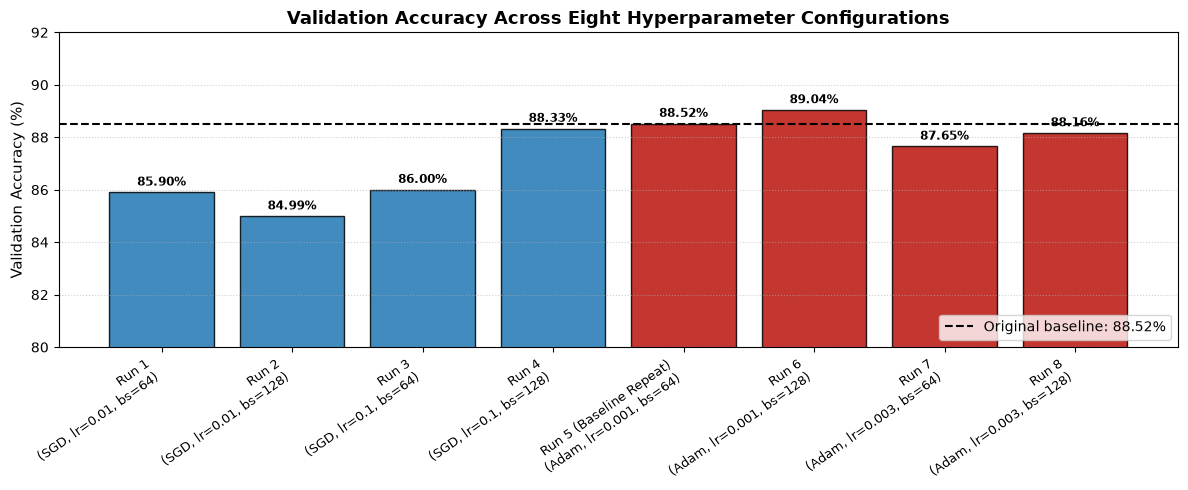

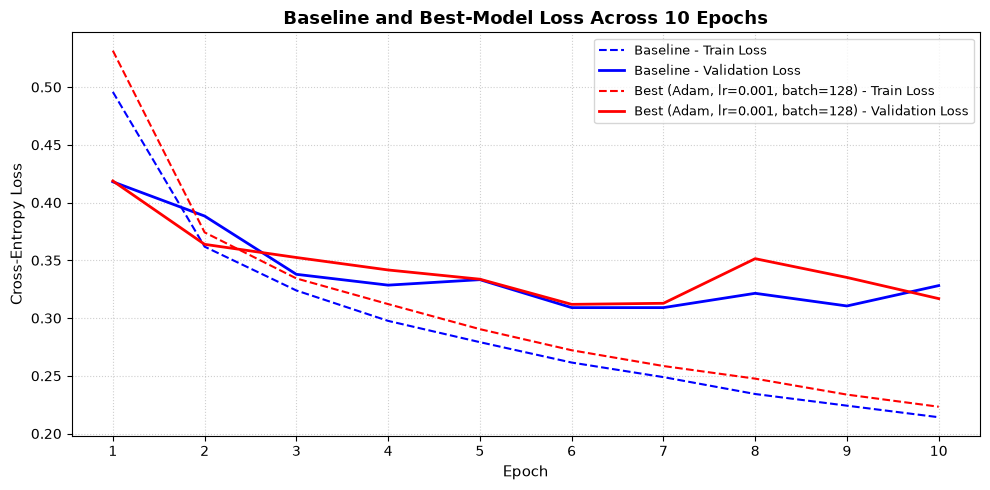

Largest directional confusion: true Shirt predicted as T-shirt/top (195 cases).
Two-way confusion between Shirt and T-shirt/top: 261 cases.


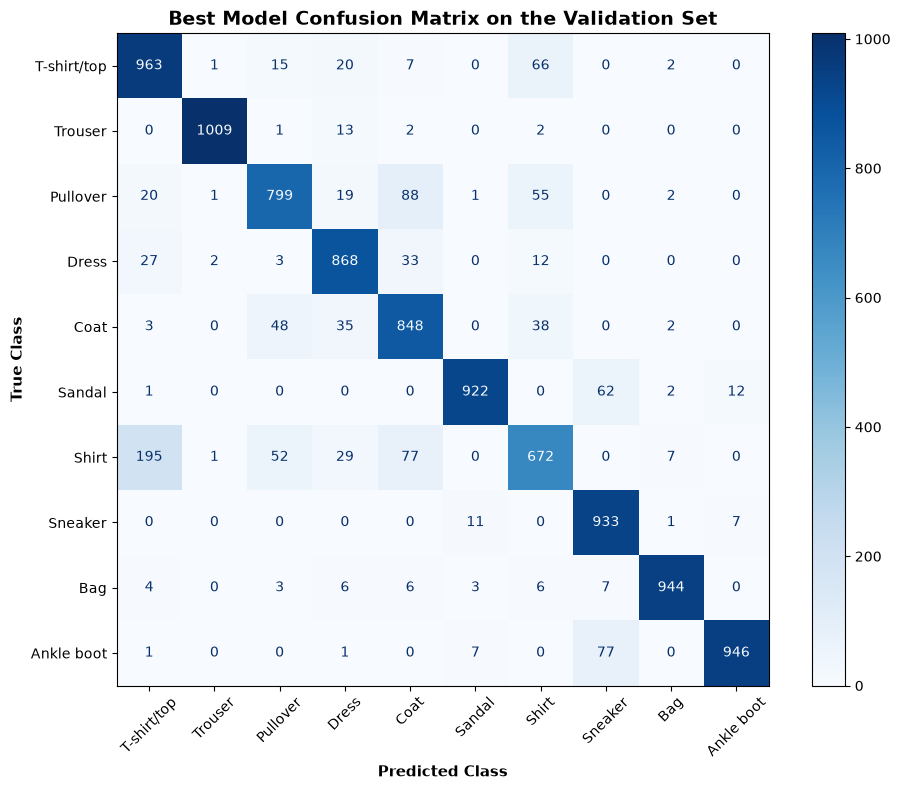

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import numpy as np
import torch
from IPython.display import display, Markdown

# Keep the original baseline distinct from the same-configuration Run 5 repeat.
baseline_row = {
    'Model / Configuration': 'Original Baseline',
    'Optimizer': 'Adam',
    'Learning Rate': 0.001,
    'Batch Size': 64,
    'Final Train Loss': baseline_history['train_loss'][-1],
    'Final Train Acc (%)': round(baseline_train_acc * 100, 2),
    'Final Val Loss': baseline_history['val_loss'][-1],
    'Final Val Acc (%)': round(baseline_history['val_acc'][-1] * 100, 2),
}
run_rows = []
for r in results:
    name = f"Run {r['Run']} (Baseline Repeat)" if r['Run'] == 5 else f"Run {r['Run']}"
    run_rows.append({
        'Model / Configuration': name,
        'Optimizer': r['Optimizer'],
        'Learning Rate': r['Learning Rate'],
        'Batch Size': r['Batch Size'],
        'Final Train Loss': r['Final Train Loss'],
        'Final Train Acc (%)': r['Final Train Acc (%)'],
        'Final Val Loss': r['Final Val Loss'],
        'Final Val Acc (%)': r['Final Val Acc (%)'],
    })
all_result_rows = [baseline_row] + run_rows

# Table 1: Training accuracy
display(Markdown("**Table 1 — Training accuracy** (original baseline and eight runs)"))
train_columns = ['Model / Configuration', 'Optimizer', 'Learning Rate', 'Batch Size',
                 'Final Train Loss', 'Final Train Acc (%)']
df_train = pd.DataFrame(all_result_rows)[train_columns].copy()
df_train['Final Train Loss'] = df_train['Final Train Loss'].round(4)
display(df_train)

# Table 2: Validation accuracy
display(Markdown("**Table 2 — Validation accuracy** (original baseline and eight runs)"))
val_columns = ['Model / Configuration', 'Optimizer', 'Learning Rate', 'Batch Size',
               'Final Val Loss', 'Final Val Acc (%)']
df_val = pd.DataFrame(all_result_rows)[val_columns].copy()
df_val['Final Val Loss'] = df_val['Final Val Loss'].round(4)
df_val['Final Val Acc (%)'] = df_val['Final Val Acc (%)'].round(2)
display(df_val)

# Visualization 1: Validation accuracy by hyperparameter configuration
labels = [
    f"Run {r['Run']}{' (Baseline Repeat)' if r['Run'] == 5 else ''}\n"
    f"({r['Optimizer']}, lr={r['Learning Rate']}, bs={r['Batch Size']})"
    for r in results
]
accuracies = [r['Final Val Acc (%)'] for r in results]
plt.figure(figsize=(12, 5))
colors = ['#1f77b4' if r['Optimizer'] == 'SGD' else '#ba140b' for r in results]
bars = plt.bar(range(len(accuracies)), accuracies, color=colors, edgecolor='black', alpha=0.85)
baseline_val_acc = baseline_history['val_acc'][-1] * 100
plt.axhline(baseline_val_acc, color='black', linestyle='--', linewidth=1.5,
            label=f"Original baseline: {baseline_val_acc:.2f}%")
plt.xticks(range(len(accuracies)), labels, rotation=35, ha='right', fontsize=9)
plt.ylabel('Validation Accuracy (%)', fontsize=11)
plt.title('Validation Accuracy Across Eight Hyperparameter Configurations', fontsize=13, fontweight='bold')
plt.ylim(80, 92)
plt.legend(loc='lower right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
for bar in bars:
    value = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.15, f'{value:.2f}%',
             ha='center', va='bottom', fontsize=8.5, fontweight='bold')
plt.tight_layout()
plt.show()

# Visualization 2: Baseline and best-model loss curves
best_label = (f"Best (Adam, lr={best_config['lr']}, "
              f"batch={best_config['batch_size']})")
epochs_range = range(1, len(baseline_history['train_loss']) + 1)
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, baseline_history['train_loss'], color='blue', linestyle='--',
         linewidth=1.5, label='Baseline - Train Loss')
plt.plot(epochs_range, baseline_history['val_loss'], color='blue', linestyle='-',
         linewidth=2, label='Baseline - Validation Loss')
plt.plot(epochs_range, best_history['train_loss'], color='red', linestyle='--',
         linewidth=1.5, label=f'{best_label} - Train Loss')
plt.plot(epochs_range, best_history['val_loss'], color='red', linestyle='-',
         linewidth=2, label=f'{best_label} - Validation Loss')
plt.title('Baseline and Best-Model Loss Across 10 Epochs', fontsize=13, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Cross-Entropy Loss', fontsize=11)
plt.xticks(epochs_range)
plt.legend(fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Visualization 3: Confusion matrix for the best model on the validation set
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]
all_preds = []
all_labels = []
best_model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        predictions = best_model(images).argmax(dim=1)
        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
true_idx, pred_idx = np.unravel_index(np.argmax(off_diagonal), off_diagonal.shape)
pair_count = cm[true_idx, pred_idx] + cm[pred_idx, true_idx]
print(f"Largest directional confusion: true {class_names[true_idx]} predicted as "
      f"{class_names[pred_idx]} ({cm[true_idx, pred_idx]} cases).")
print(f"Two-way confusion between {class_names[true_idx]} and {class_names[pred_idx]}: "
      f"{pair_count} cases.")

fig, ax = plt.subplots(figsize=(10, 8))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45, values_format='d')
plt.title('Best Model Confusion Matrix on the Validation Set', fontsize=14, fontweight='bold')
plt.ylabel('True Class', fontsize=11, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## Part 4: Interpretation of Results and Discussion [4 Marks]

### Experimental results
The original baseline used Adam with a learning rate of 0.001 and batch size 64 for 10 epochs. Its measured training accuracy was **92.20%** and validation accuracy was **88.52%**. Run 5 repeats those same hyperparameters as part of the eight-run search; its results are shown separately as **Run 5 (Baseline Repeat)**, not as the original baseline. The search's best result was Run 6 (Adam, learning rate 0.001, batch size 128): **89.04%** validation accuracy and **0.3168** validation loss. This is a modest **0.52 percentage-point** improvement over the original baseline, whose validation loss was **0.3281**.

### Hyperparameter influence
The validation-accuracy plot and tables show that the effect of learning rate depends on the optimizer. Compare rates within each optimizer: with SGD, increasing the rate from 0.01 to 0.10 changed validation accuracy from 85.90% to 86.00% at batch size 64, and from 84.99% to 88.33% at batch size 128. With Adam, increasing the rate from 0.001 to 0.003 reduced accuracy by about 0.9 percentage points at each batch size (88.52% to 87.65% at 64; 89.04% to 88.16% at 128). Batch size was not uniformly beneficial: changing 64 to 128 reduced accuracy by 0.91 points for SGD at 0.01, but improved it by 2.33 points for SGD at 0.10 and by about 0.5 points for each Adam rate. Adam's configurations scored higher overall in this tested grid, but the SGD and Adam learning-rate values differ, so this experiment does not isolate optimizer choice at a matched rate.

### Convergence and overfitting
Both training-loss curves fall throughout the 10 epochs. Validation loss improves quickly at first, reaches its low point around epochs 6–7, then fluctuates rather than continuing to improve; the best model's validation loss also rises visibly at epoch 8 before falling to 0.3168 at epoch 10. The final training-to-validation accuracy gaps are 3.68 points for the baseline (92.20% versus 88.52%) and 3.38 points for Run 6 (92.42% versus 89.04%). Together, the widening separation in the later loss curves and these final gaps are evidence of some overfitting. Run 6 ends with better validation accuracy and loss, but one run does not establish that batch size 128 itself regularizes the model or that tuning eliminated overfitting.

### Confusion matrix and conclusion
The largest off-diagonal entry is **Shirt predicted as T-shirt/top (195 validation images)**; the reverse error is 66 images, for 261 confusions across the pair. In my view, this is plausible because both are upper-body garments with similar silhouettes in small 28 × 28 grayscale images; details such as collars and sleeves occupy few pixels. The MLP also flattens the image, so it does not explicitly preserve local two-dimensional patterns as a convolutional model would.

The main limitation is the narrow search: only eight configurations, one fixed split/seed, and 10 epochs were tested. A useful next step would be a broader, repeated comparison (including matched learning-rate choices and a CNN baseline) to check whether the small validation gain is robust.